In [1]:
!pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 9.4 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=eb09299d5b9adb809011eb9c6504445c1311b56c226dcf3fe5aa8fe62f3e9a02
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


In [2]:
# ESSENTIALS
import pandas as pd
import numpy as np

# PLOTTING
import matplotlib.pyplot as plt
import seaborn as sns

# FIDELITY
from scipy.stats import chi2, chi2_contingency, ks_2samp
from scipy.stats import zscore

# COMPUTATIONAL UTILITY
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, r2_score

# SURVIVAL ANALYSIS
from statsmodels.stats.multitest import multipletests
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from lifelines.utils import concordance_index

# PRIVACY
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances
from sklearn.metrics import roc_auc_score
from scipy.stats import chi2, chi2_contingency, ks_2samp, fisher_exact

# IMPORTANT

In [3]:
colors = {"GC":"red", "CTGAN":"blue", "C-GAN":"purple", "TVAE":"green"}
model = "TVAE" # select the model from the dictionary keys

# Data loading

In [4]:
# INPUT: Real dataset
df_real = pd.read_parquet("/content/final_dataset.parquet")
df_real = df_real.convert_dtypes()
df_real = df_real.drop(columns="Patient_ID")
df_real.head()

,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,COPD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,0,84,30.12,1,3,0,1,0,0,0,...,0,0,0,1,0,27,1322,1322,1,0
1,1,85,34.72,0,3,0,1,1,0,0,...,0,1,0,0,0,11,235,123,1,0
2,1,85,28.96,0,2,0,0,0,0,0,...,0,0,0,0,0,4,2291,2291,0,0
3,1,84,28.3,0,3,0,1,1,1,0,...,0,0,0,0,0,16,1058,1058,0,0
4,1,64,38.37,0,2,1,0,1,0,0,...,0,0,0,1,1,19,2111,1385,0,1


In [5]:
# INPUT: Train dataset
df_train = pd.read_parquet("/content/train_df_seed42.parquet")
df_train = df_train.drop(columns="Patient_ID")
df_train.head()

,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,COPD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,1,86,31.47,0,3,0,0,1,1,0,...,0,0,0,0,0,7,1758,545,1,0
1,1,75,21.30,2,2,0,0,0,0,0,...,0,0,0,0,0,39,39,39,1,0
2,1,75,25.00,0,3,1,1,1,0,0,...,0,0,0,0,0,8,797,797,0,0
3,1,87,28.13,0,3,1,1,0,0,1,...,0,0,0,0,0,9,236,77,1,0
4,0,78,27.13,0,3,1,1,1,0,0,...,0,0,0,0,1,6,2066,2066,0,0


In [6]:
# INPUT: Test dataset
df_test = pd.read_parquet("/content/test_df_seed42.parquet")
df_test = df_test.drop(columns="Patient_ID")
df_test.head()

,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,COPD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,1,85,34.72,0,3,0,1,1,0,0,...,0,1,0,0,0,11,235,123,1,0
1,1,64,22.21,0,2,0,0,0,0,0,...,0,0,0,0,0,6,2086,2086,0,0
2,0,58,34.96,2,3,0,1,0,0,0,...,0,0,0,0,0,14,2828,2828,0,0
3,0,61,25.40,1,3,1,0,0,0,0,...,0,0,0,0,0,6,2464,2464,0,0
4,1,60,27.30,0,2,1,1,0,0,0,...,0,0,0,0,0,50,2270,2270,0,0


In [7]:
# INPUT: Synthetic dataset
df_synth = pd.read_parquet("/content/tvae_result_best.parquet")
df_synth = df_synth.drop(columns="Patient_ID")
df_synth.head()

,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,COPD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,0,51,26.58,2,2,1,1,0,0,0,...,0,0,0,0,0,14,2676,2519,0,0
1,1,64,23.64,0,2,1,0,1,0,0,...,0,0,0,0,0,8,3267,2601,0,0
2,0,76,26.60,1,2,0,1,0,0,0,...,0,0,0,0,0,16,1129,831,1,1
3,1,81,23.72,1,2,0,0,0,0,0,...,0,0,0,0,0,6,2975,2423,0,0
4,1,76,23.20,0,2,1,1,0,0,0,...,0,0,0,0,0,7,1957,1852,1,0


Locate the continuous and categorical columns

In [8]:
cont_cols = ["Age", "BMI", "Node_ratio", "LOS_days", "Survival_days", "Recurrence_free_days"]
cat_cols = [col for col in df_real.columns if col not in cont_cols]

Time and event columns (for survival analysis)

In [9]:
time_col = "Survival_days"
event_col = "Death"

**FINAL OUTPUT:**

Real dataset: df_real

Train and test datasets: df_train, df_test

Synthetic dataset: df_synth

List of continuous columns: cont_cols

List of categorical columns: cat_cols

Time column: time_col

Event column: event_col

# Fidelity

Goal: the synthetic data has to look like the real data, both in terms of individual columns and the relationships between them

In [ ]:
# FALSE DISCOVERY RATE
# Benjamini-Hochberg correction
def benjamini_hochberg(pvals):
    p = np.asarray(pvals, dtype=float)
    valid_mask = np.isfinite(p)
    qvals = np.full_like(p, np.nan)
    _, qvals[valid_mask], _, _ = multipletests(p[valid_mask], method='fdr_bh')
    return qvals

def add_fdr_significance_columns(df: pd.DataFrame, p_col: str, q_col: str,
                                 alpha: float = 0.05, sig_value_col: str = 'significant_value',
                                 sig_fdr_col: str = 'significant_fdr') -> pd.DataFrame:
    out = df.copy()
    if p_col not in out.columns or len(out) == 0:
        out[sig_value_col] = False
        out[sig_fdr_col] = False
        return out

    pvals = pd.to_numeric(out[p_col], errors='coerce')
    out[p_col] = pvals
    out[q_col] = benjamini_hochberg(pvals.values)

    out[sig_value_col] = (out[p_col] < alpha).fillna(False)
    out[sig_fdr_col] = (pd.to_numeric(out[q_col], errors='coerce') < alpha).fillna(False)

    for base_col in ('smd_difference_level', 'cramer_difference_level'):
        if base_col in out.columns:
            out[f'{base_col}_fdr'] = np.where(out[sig_fdr_col], out[base_col], 'no_significant_fdr')

    return out

**Metric 1: Kolmogorov-Smirnov (KS) Test and Mean Square Difference (SMD)**

Goal: p-value > 0.05

NOTE: these tests are only for continuous quantitative data

In [ ]:
# DFR = real dataframe, DFS = synthetic dataframe, cont_cols = continuous columns
def quant_fidelity(DFR, DFS, cont_cols):
    report = []

    for col in cont_cols:
        real_data  = pd.to_numeric(DFR[col], errors='coerce').dropna()
        synth_data = pd.to_numeric(DFS[col], errors='coerce').dropna()

        if len(real_data) < 2 or len(synth_data) < 2:
            report.append({
                'Column': col, 'KS_Stat': np.nan, 'KS_pval': np.nan,
                'SMD': np.nan, 'KS_Status': 'Missing data',
                'SMD_Status': 'Missing data'
            })
            continue

        ks_stat, ks_pval = ks_2samp(real_data, synth_data)

        mean_r, mean_s = real_data.mean(), synth_data.mean()
        std_r,  std_s  = real_data.std(),  synth_data.std()
        pooled_var = (std_r**2 + std_s**2) / 2
        if pooled_var == 0:
            smd = 0.0 if mean_r == mean_s else np.inf
        else:
            smd = (mean_r - mean_s) / np.sqrt(pooled_var)

        report.append({
            'Column':     col,
            'KS_Stat':    round(ks_stat, 4),
            'KS_pval':    round(ks_pval, 4),
            'SMD':        round(smd, 4),
            'SMD_Status': 'Pass' if abs(smd) < 0.2 else 'Fail'
        })

    result_df = pd.DataFrame(report)
    # Benjamini-Hochberg correction
    result_df = add_fdr_significance_columns(
        result_df,
        p_col='KS_pval',
        q_col='KS_qval',
    )
    result_df['KS_Status'] = result_df.apply(
        lambda row: 'Missing data' if pd.isna(row['KS_pval'])
                    else ('Pass' if not row['significant_fdr'] else 'Fail'),
        axis=1
    )
    return result_df

results_ks_smd = quant_fidelity(df_real, df_synth, cont_cols)
results_ks_smd

,Column,KS_Stat,KS_pval,SMD,SMD_Status,KS_qval,significant_value,significant_fdr,KS_Status
0,Age,0.0652,0.4424,-0.0505,Pass,0.66360,False,False,Pass
1,BMI,0.0595,0.5606,-0.0266,Pass,0.67272,False,False,Pass
2,Node_ratio,0.2455,0.0000,0.1854,Pass,0.00000,True,True,Fail
3,LOS_days,0.0538,0.6868,0.0273,Pass,0.68680,False,False,Pass
4,Survival_days,0.0737,0.2940,0.0266,Pass,0.58800,False,False,Pass
5,Recurrence_free_days,0.0935,0.0914,-0.0551,Pass,0.27420,False,False,Pass


In [ ]:
results_ks_smd.to_csv("ks_smd_%s.csv" % model)

**Metric 2: Chi square and Cramer's V**

Goal: p-value > 0.05 and V < 0.1

NOTE: these tests are only for categorical data

In [ ]:
# DFR = real dataframe, DFS = synthetic dataframe, cat_cols = categorical columns
def qual_fidelity(DFR, DFS, cat_cols):
    report = []
    common_cat_cols = [col for col in cat_cols if col in DFR.columns and col in DFS.columns]

    for col in common_cat_cols:
        real_vc  = DFR[col].value_counts()
        synth_vc = DFS[col].value_counts()

        obs_df    = pd.concat([real_vc, synth_vc], axis=1, keys=['real', 'synth']).fillna(0)
        obs_array = obs_df.values.astype(int)

        chi2_stat, p, v = np.nan, np.nan, np.nan
        test_used = 'N/A'

        if obs_array.shape[0] < 2 or obs_array.shape[1] < 2:
            chi2_status = 'Not enough data or invalid table'
            v_status    = 'Not enough data or invalid table'
        else:
            try:
                # Calcular Chi² y capturar las frecuencias esperadas
                chi2_stat, p_chi2, _, expected = chi2_contingency(obs_array)
                low_expected = (expected < 5).any()

                # Decidir qué test usar según las frecuencias esperadas
                if not low_expected:
                    # Todas las celdas tienen freq esperada >= 5 → Chi² estándar
                    p = p_chi2
                    test_used = 'Chi²'
                elif obs_array.shape == (2, 2):
                    # Hay celdas pequeñas y la tabla es 2x2 → Fisher exacto
                    _, p = fisher_exact(obs_array)
                    test_used = 'Fisher exacto'
                else:
                    # Hay celdas pequeñas y la tabla es más grande → G-test
                    chi2_stat_sim, p_sim, _, _ = chi2_contingency(
                        obs_array, lambda_="log-likelihood"
                    )
                    p = p_sim
                    test_used = 'Chi² G-test'

                # Cramér's V (igual que antes)
                n = obs_array.sum()
                denominator = n * (min(obs_array.shape) - 1)
                if denominator == 0:
                    v = np.nan if chi2_stat > 0 else 0
                else:
                    v = np.sqrt(chi2_stat / denominator)
                v_status = 'Pass' if v < 0.1 else 'Fail'

            except ValueError as e:
                if 'expected frequencies has a zero element' in str(e):
                    chi2_status = 'Not enough data for Chi2'
                    v_status    = "Not enough data for Cramer's V"
                else:
                    chi2_status = f'Error: {e}'
                    v_status    = f'Error: {e}'

        report.append({
            'Column':         col,
            'Test_used':      test_used,
            'Chi2_pval':      round(p, 4) if not pd.isna(p) else p,
            "V de Cramér":    round(v, 4) if not pd.isna(v) else v,
            "Cramér's V Status": v_status
        })

    result_df = pd.DataFrame(report)
    # Benjamini-Hochberg correction
    result_df = add_fdr_significance_columns(
        result_df,
        p_col='Chi2_pval',
        q_col='Chi2_qval',
    )
    result_df['Chi2_Status'] = result_df.apply(
        lambda row: 'Not enough data for Chi2' if pd.isna(row['Chi2_pval'])
                    else ('Pass' if not row['significant_fdr'] else 'Fail'),
        axis=1
    )
    return result_df

results_chi2 = qual_fidelity(df_real, df_synth, cat_cols)
results_chi2

,Column,Test_used,Chi2_pval,V de Cramér,Cramér's V Status,Chi2_qval,significant_value,significant_fdr,Chi2_Status
0,Sex,Chi²,0.8795,0.0057,Pass,0.920500,False,False,Pass
1,Smoking_Status,Chi²,0.6838,0.0328,Pass,0.886407,False,False,Pass
2,ASA,Chi²,0.0062,0.1327,Fail,0.035875,True,True,Fail
3,T2DM,Chi²,0.8021,0.0094,Pass,0.920500,False,False,Pass
4,HTN,Chi²,0.5907,0.0202,Pass,0.826980,False,False,Pass
5,Dl,Chi²,0.8165,0.0087,Pass,0.920500,False,False,Pass
6,IHD,Chi²,0.0029,0.1119,Fail,0.025375,True,True,Fail
7,COPD,Chi²,0.0101,0.0968,Pass,0.039278,True,True,Fail
8,CKD,Chi²,0.1407,0.0554,Pass,0.328300,False,False,Pass
9,IS,Chi²,0.0532,0.0728,Pass,0.155167,False,False,Pass


In [ ]:
results_chi2.to_csv("chi2_%s.csv" % model)

# Computational utility

**Metrics 1 and 2: F1-Score and R2-Score**

Goal: check if the synthetic data classifies (F1) or regresses (R2) data as well as the real dataset, i.e., a utility ratio > 0.8

NOTE: F1 is for categorical data, R2 for numerical data

In [10]:
# HELPER FUNCTION - for utility and privacy
def prepare_data_for_ml_model(X_raw_train, X_raw_test, X_raw_synth):
    datasets = [X_raw_train, X_raw_test, X_raw_synth]

    encoded = [pd.get_dummies(X) for X in datasets]
    all_cols = list(set().union(*[X.columns for X in encoded]))

    return tuple(
        X.reindex(columns=all_cols, fill_value=0)
          .apply(pd.to_numeric, errors='coerce')
          .fillna(0)
        for X in encoded
    )

In [11]:
# RANDOM FOREST - for utility and privacy
# clasif = the ML task we're doing is classification - True by default
def random_forest(X_train, y_train, X_test, clasif=True):
    ModelClass = RandomForestClassifier if clasif else RandomForestRegressor
    model = ModelClass(n_estimators=50, max_depth=5, random_state=42)
    model.fit(X_train, y_train)
    return model, model.predict(X_test)

In [12]:
# SCORES
# r = real, s = synthetic
def calculate_scores(X_r_train_processed, y_r_train_raw, X_r_test_processed,
                     y_r_test_raw, X_s_processed, y_s_raw, clasif=True):

    # Conversion of raw target columns into model-ready numbers
    def prepare_target(series):
        if clasif:
            return series.astype('category').cat.codes # encode categories as integers
        numeric_series = pd.to_numeric(series, errors='coerce')
        return numeric_series.fillna(numeric_series.mean() if not numeric_series.isnull().all() else 0) # fill missing values with mean

    y_r_train_final, y_r_test_final, y_s_final = [
        prepare_target(y) for y in (y_r_train_raw, y_r_test_raw, y_s_raw)
    ]

    # Exit if not enough data
    if clasif and (y_r_train_final.nunique() < 2 or y_s_final.nunique() < 2):
        return None, None

    # Score computation
    score_fn = f1_score if clasif else r2_score
    score_kwargs = {"average": "weighted", "zero_division": 0} if clasif else {}

    scores = []
    for X_train, y_train in [(X_r_train_processed, y_r_train_final), (X_s_processed, y_s_final)]:
        _, preds = random_forest(X_train, y_train, X_r_test_processed, clasif)
        scores.append(score_fn(y_r_test_final, preds, **score_kwargs))

    return tuple(scores)

In [13]:
# SCORES OF ALL COLUMNS
# DFR_full = full real dataset, DFS = full synthetic dataset
# DFR_train = real train dataset, DFR_test = real test dataset
def utility(DFR_full, DFS_full, DFR_train, DFR_test):
    utility_scores = []
    for col in DFR_full.columns:
      # If not enough data
        if DFR_train[col].dropna().empty or \
           DFR_test[col].dropna().empty or \
           DFS_full[col].dropna().empty:
            print(f"Skipping {col}: Empty or all-NaN in one of the sets.")
            continue
        # Prepare data for ML model
        X_r_train_raw = DFR_train.drop(columns=[col])
        y_r_train_raw = DFR_train[col]

        X_r_test_raw = DFR_test.drop(columns=[col])
        y_r_test_raw = DFR_test[col]

        X_s_raw = DFS_full.drop(columns=[col])
        y_s_raw = DFS_full[col]

        X_r_train_processed, X_r_test_processed, X_s_processed = prepare_data_for_ml_model(X_r_train_raw, X_r_test_raw, X_s_raw)

        # Check if we should do classification or regression
        # Usar la lista explícita cont_cols como fuente de verdad
        is_classification = col not in cont_cols

        # Calculate scores
        score_r, score_s = calculate_scores(X_r_train_processed, y_r_train_raw,
                                            X_r_test_processed, y_r_test_raw,
                                            X_s_processed, y_s_raw, is_classification)

        if score_r is None or score_s is None:
            print(f"Skipping {col}: Scores could not be calculated.")
            continue

        # Lógica diferente según clasificación/regresión
        if is_classification:
            # F1: usar ratio
            util_value = round(score_s / (score_r + 1e-9), 4)
            status = 'Pass' if util_value > 0.8 else 'Fail'

        else:
            # R²: usar diferencia, y saltar si el real no es informativo
            if score_r < 0.1:
                util_value = np.nan
                status = 'Skip (real model uninformative)'
            else:
                delta = score_r - score_s
                util_value = round(delta, 4)
                status = 'Pass' if delta < 0.10 else 'Fail'

        # Report
        utility_scores.append({
            'Variable': col,
            'Real yield (Test)': round(score_r, 4),
            'Synth yield (Test)': round(score_s, 4),
            'Utility value': util_value,
            'Status': status
        })

    return pd.DataFrame(utility_scores)

results_util = utility(df_real, df_synth, df_train, df_test)
results_util

,Variable,Real yield (Test),Synth yield (Test),Utility value,Status
0,Sex,0.8163,0.5948,0.7287,Fail
1,Age,0.2940,0.0774,0.2166,Fail
2,BMI,0.0159,0.0705,NaN,Skip (real model uninformative)
3,Smoking_Status,0.5429,0.4804,0.8849,Pass
4,ASA,0.5285,0.5023,0.9505,Pass
5,T2DM,0.5273,0.5589,1.0598,Pass
6,HTN,0.7056,0.6058,0.8586,Pass
7,Dl,0.6504,0.6363,0.9784,Pass
8,IHD,0.8141,0.8141,1.0000,Pass
9,COPD,0.8957,0.8957,1.0000,Pass


In [14]:
results_util

,Variable,Real yield (Test),Synth yield (Test),Utility value,Status
0,Sex,0.8163,0.5948,0.7287,Fail
1,Age,0.2940,0.0774,0.2166,Fail
2,BMI,0.0159,0.0705,NaN,Skip (real model uninformative)
3,Smoking_Status,0.5429,0.4804,0.8849,Pass
4,ASA,0.5285,0.5023,0.9505,Pass
5,T2DM,0.5273,0.5589,1.0598,Pass
6,HTN,0.7056,0.6058,0.8586,Pass
7,Dl,0.6504,0.6363,0.9784,Pass
8,IHD,0.8141,0.8141,1.0000,Pass
9,COPD,0.8957,0.8957,1.0000,Pass


In [15]:
results_util.to_csv("util_%s.csv" % model)

# Clinical utility: Survival analysis

**Metric 1: Kaplan-Meier**

Goal: check if the KM curve is similar in both datasets

In [ ]:
# DATA PREPARATION
def prepare_survival(df, time_col, event_col):
    tmp = df[[time_col, event_col]].copy()
    for col in (time_col, event_col):
        tmp[col] = pd.to_numeric(tmp[col], errors='coerce')
    tmp = tmp.dropna()
    tmp = tmp[tmp[time_col] >= 0]
    return tmp, [{'name': 'survival', 'time_col': time_col, 'event_col': event_col}]

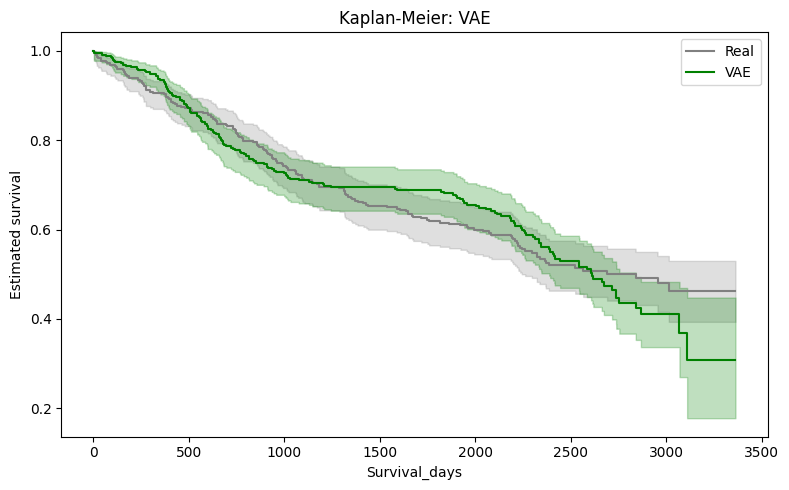

KM median real: 2839.0000 | synthetic: 2613.0000 | log-rank stat: 0.0400 | p-value: 0.841421


In [ ]:
# KAPLAN-MEIER ANALYSIS: PLOT AND LOG-RANK TEST
# DFR = real dataset, DFS = synthetic dataset, time_col = time column, event_col = event column
def km_analysis(DFR, DFS, time_col, event_col):
    real_surv, _ = prepare_survival(DFR, time_col, event_col)
    syn_surv, _  = prepare_survival(DFS, time_col, event_col)

    if len(real_surv) < 2 or len(syn_surv) < 2:
        print("KM omitted: not enough valid rows after cleaning.")
        return

    try:
        km_real = KaplanMeierFitter(label='Real').fit(real_surv[time_col], event_observed=real_surv[event_col])
        km_syn  = KaplanMeierFitter(label=model).fit(syn_surv[time_col], event_observed=syn_surv[event_col])

        plt.figure(figsize=(8, 5))
        km_real.plot_survival_function(ci_show=True, color="grey")
        km_syn.plot_survival_function(ci_show=True, color=colors[model])
        plt.title(f'Kaplan-Meier: {model}')
        plt.xlabel(time_col)
        plt.ylabel('Estimated survival')
        plt.tight_layout()
        plt.savefig(f"km_{model}.png")
        plt.show()

        lr = logrank_test(
            real_surv[time_col], syn_surv[time_col],
            event_observed_A=real_surv[event_col],
            event_observed_B=syn_surv[event_col],
        )

        print(f"KM median real: {km_real.median_survival_time_:.4f} | "
              f"synthetic: {km_syn.median_survival_time_:.4f} | "
              f"log-rank stat: {lr.test_statistic:.4f} | p-value: {lr.p_value:.6f}")

        # Benjamini-Hochberg correction
        return add_fdr_significance_columns(
            pd.DataFrame([{
                'endpoint': 'survival', 'time_col': time_col, 'event_col': event_col,
                'n_real': len(real_surv), 'n_syn': len(syn_surv),
                'events_real': float(real_surv[event_col].sum()),
                'events_syn':  float(syn_surv[event_col].sum()),
                'median_real_km': float(km_real.median_survival_time_),
                'median_syn_km':  float(km_syn.median_survival_time_),
                'median_diff_km': float(km_real.median_survival_time_ - km_syn.median_survival_time_),
                'logrank_stat': float(lr.test_statistic),
                'logrank_pvalue': float(lr.p_value),
            }]),
            p_col='logrank_pvalue',
            q_col='logrank_qvalue',
        )

    except Exception as exc:
        print(f"KM could not be calculated: {exc}")


results_km = km_analysis(df_real, df_synth, time_col, event_col)

In [ ]:
results_km

,endpoint,time_col,event_col,n_real,n_syn,events_real,events_syn,median_real_km,median_syn_km,median_diff_km,logrank_stat,logrank_pvalue,logrank_qvalue,significant_value,significant_fdr
0,survival,Survival_days,Death,353,353,162.0,161.0,2839.0,2613.0,226.0,0.040031,0.841421,0.841421,False,False


In [ ]:
results_km.to_csv("km_%s.csv" % model)

**Metric 2: Cox Regression**

Goal: check if the Cox regression models are similar

In [ ]:
# DEFINE COVARIATES
# Age is modelled as a natural cubic spline (df=4) instead of being replaced by NAT,
# following the sensitivity analysis showing better fit (concordance, log-likelihood,
# partial AIC) for the spline specification versus the NAT substitution (see
# Supplementary Section 11.5).
COVARS = ['Age', 'TNM_stage', 'Node_ratio', 'Adjuvant_CT', 'R_grade', 'Approach', 'Complications']

AGE_COL = 'Age'
AGE_SPLINE_DF = 4

VARIANCE_THRESHOLD = 0.01
PENALIZER         = 0.1
SIGN_AGR_THRESHOLD = 0.95
MAGNITUDE_THRESHOLD = 0.1


**Age spline basis**

The spline knots are fitted ONCE on the real data and then reused (not refit) on every
synthetic dataset, so that `Age_spline_i` terms represent the same functional basis and
remain comparable across models. Refitting the knots separately per dataset would make
the Age coefficients incomparable between real and synthetic Cox models.


In [ ]:
# AGE SPLINE BASIS HELPERS
from patsy import dmatrix, build_design_matrices

def fit_age_spline_basis(df, age_col=AGE_COL, df_splines=AGE_SPLINE_DF):
    """Fit the natural cubic spline basis (knots) on a dataset (intended to be
    the REAL data). Returns the basis (DataFrame) and the design_info object needed
    to apply the SAME knots to other datasets via apply_age_spline_basis()."""
    basis = dmatrix(f"cr({age_col}, df={df_splines}) - 1", data=df, return_type="dataframe")
    basis.columns = [f"{age_col}_spline_{i+1}" for i in range(basis.shape[1])]
    basis.index = df.index
    return basis, basis.design_info


def apply_age_spline_basis(df, design_info, age_col=AGE_COL, df_splines=AGE_SPLINE_DF):
    """Apply a previously fitted spline basis (design_info from fit_age_spline_basis)
    to a new dataset (e.g. a synthetic cohort), so the knots match those learned
    from the real data."""
    new_basis = build_design_matrices([design_info], df)[0]
    new_basis = pd.DataFrame(
        np.asarray(new_basis),
        columns=[f"{age_col}_spline_{i+1}" for i in range(new_basis.shape[1])],
        index=df.index
    )
    return new_basis


In [ ]:
# FIT COX MODELS
def cox_fitting(df, time_col, event_col, covariates,
                variance_threshold=VARIANCE_THRESHOLD, penalizer=PENALIZER,
                age_col=AGE_COL, age_design_info=None):
    """
    Fits a Cox model. Age is replaced by its natural cubic spline basis instead of
    being included as a single linear term.

    - age_design_info=None  -> fit new spline knots on `df` (use for the REAL data).
    - age_design_info=<obj> -> reuse previously fitted knots (use for SYNTHETIC data,
      passing in the design_info returned when fitting the real model), so that Age
      spline terms are comparable across models.

    Returns (cph, data, age_design_info) — the design_info is returned in both cases
    so it can be threaded into the next call for a synthetic dataset.
    """
    cols = [time_col, event_col] + covariates
    data_raw = df[cols].dropna()

    if age_design_info is None:
        age_basis, age_design_info = fit_age_spline_basis(data_raw, age_col=age_col)
    else:
        age_basis = apply_age_spline_basis(data_raw, age_design_info, age_col=age_col)

    remaining_covariates = [c for c in covariates if c != age_col]
    cat_cols_local = [c for c in remaining_covariates if not pd.api.types.is_numeric_dtype(data_raw[c])]
    data_other = pd.get_dummies(
        data_raw[[time_col, event_col] + remaining_covariates],
        columns=cat_cols_local
    )

    data = pd.concat([age_basis, data_other], axis=1)

    covariate_cols = [c for c in data.columns if c not in (time_col, event_col)]
    events = data[event_col].astype(bool)

    low_var = [
        c for c in covariate_cols
        if data[c].var() < variance_threshold
        or data.loc[events, c].var() < variance_threshold
        or data.loc[~events, c].var() < variance_threshold
    ]
    if low_var:
        print(f"Dropping low-variance columns: {low_var}")
        data = data.drop(columns=low_var)

    data = data.apply(
        lambda s: s.astype(s.dtype.numpy_dtype) if hasattr(s.dtype, 'numpy_dtype') else s
    )

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(data, duration_col=time_col, event_col=event_col)
    return cph, data, age_design_info


In [ ]:
# CHECK VALIDITY FOR CHI SQUARE
def check_chi2_validity(df_real, df_synth, cat_cols):
    print("=== Variables with expected frequency < 5 ===\n")
    problematic, ok_vars = [], []

    for col in cat_cols:
        if col not in df_real.columns or col not in df_synth.columns:
            continue
        obs_array = (
            pd.concat(
                [df_real[col].value_counts(), df_synth[col].value_counts()],
                axis=1, keys=['real', 'synth']
            )
            .fillna(0).values.astype(int)
        )
        if obs_array.shape[0] < 2 or obs_array.shape[1] < 2:
            continue
        try:
            _, _, _, expected = chi2_contingency(obs_array)
            if expected.min() < 5:
                problematic.append({
                    'Variable': col,
                    'Categories': obs_array.shape[0],
                    'Minimum expected freq': round(expected.min(), 2),
                    'Cells with freq < 5': (expected < 5).sum(),
                    'Total cells': expected.size,
                    'Recommended test': 'Exact Fisher' if obs_array.shape == (2, 2) else 'G-test',
                })
            else:
                ok_vars.append(col)
        except Exception as e:
            print(f"  Error in {col}: {e}")

    print(f"Total categorical variables: {len(cat_cols)}")
    print(f"Variables OK for standard Chi²: {len(ok_vars)}")
    print(f"Problematic variables: {len(problematic)}\n")
    if problematic:
        print("=== Problematic variables ===")
        print(pd.DataFrame(problematic).to_string(index=False))
    else:
        print("✅ All variables are valid for standard Chi².")

In [ ]:
# SIGN AGREEMENT
def compute_sign_agreement(params_real, params_synth, label="", magnitude_threshold=None):
    if magnitude_threshold is not None:
        mask = params_real.abs() >= magnitude_threshold
        params_real  = params_real[mask]
        params_synth = params_synth[mask]
        label = f"{label} (|coef_real| ≥ {magnitude_threshold})"

    agreement  = (np.sign(params_real) == np.sign(params_synth)).mean()
    flipped    = params_real.index[np.sign(params_real) != np.sign(params_synth)].tolist()
    status     = "✅ Pass" if agreement >= SIGN_AGR_THRESHOLD else "❌ Fail"

    print(f"\n=== Sign Agreement {label} ===")
    if magnitude_threshold is not None:
        print(f"Evaluted covariates: {len(params_real)}")
    print(f"Sign agreement: {agreement * 100:.2f}%")
    print(f"Status: {status} (threshold ≥ {SIGN_AGR_THRESHOLD * 100:.0f}%)")

    if flipped:
        print(f"\n⚠ Covariates with flipped sign ({len(flipped)}):")
        print(pd.DataFrame({
            'Covariate': flipped,
            'Coef_Real':  params_real[flipped].round(4).values,
            'Coef_Synth': params_synth[flipped].round(4).values,
        }).to_string(index=False))

    return agreement

In [ ]:
# HAZARD RATIO COMPARISON
def compare_hazard_ratios(cph_real, cph_synth, shared, csv_path):
    hr_real  = np.exp(cph_real.params_.loc[shared])
    hr_synth = np.exp(cph_synth.params_.loc[shared])

    hr_df = pd.DataFrame({
        'HR_Real':    hr_real.round(4),
        'HR_Synth':   hr_synth.round(4),
        'HR_Ratio':   (hr_synth / hr_real).round(4),        # 1.0 = perfect match
        'HR_AbsDiff': (hr_synth - hr_real).abs().round(4),
    })

    corr          = hr_real.corr(hr_synth)
    mean_abs_diff = hr_df['HR_AbsDiff'].mean()

    print(f"\n=== Hazard Ratio Comparison ===")
    print(f"HR correlation (real vs synthetic): {corr:.4f}")
    print(f"Mean absolute HR difference:        {mean_abs_diff:.4f}")
    print(f"Per-covariate breakdown saved to:   {csv_path}")

    hr_df.to_csv(csv_path, index_label='Covariate')
    return hr_df

In [ ]:
# CONFIDENCE INTERVAL COMPARISON
def compare_confidence_intervals(cph_real, cph_synth, shared, csv_path):
    """
    Metrics:
      - Overlap rate: % of covariates where the synthetic CI overlaps the real CI
      - Width ratio:  synthetic CI width / real CI width (1.0 = same width)
      - Coverage rate: % of covariates where the real point estimate falls
                       inside the synthetic CI (and vice versa)
    """
    summary_real  = cph_real.summary.loc[shared,  ['exp(coef) lower 95%', 'exp(coef) upper 95%']]
    summary_synth = cph_synth.summary.loc[shared, ['exp(coef) lower 95%', 'exp(coef) upper 95%']]

    lo_r, hi_r = summary_real['exp(coef) lower 95%'],  summary_real['exp(coef) upper 95%']
    lo_s, hi_s = summary_synth['exp(coef) lower 95%'], summary_synth['exp(coef) upper 95%']

    # CI overlap: intervals overlap when max(lo) < min(hi)
    overlap     = np.maximum(lo_r, lo_s) < np.minimum(hi_r, hi_s)
    overlap_rate = overlap.mean()

    # CI width ratio
    width_real  = hi_r - lo_r
    width_synth = hi_s - lo_s
    width_ratio = (width_synth / width_real).replace([np.inf, -np.inf], np.nan)

    # Coverage: does real HR point estimate fall inside synthetic HR CI?
    hr_real  = cph_real.summary.loc[shared,  'exp(coef)']
    hr_synth = cph_synth.summary.loc[shared, 'exp(coef)']
    coverage_real_in_synth = ((hr_real  >= lo_s) & (hr_real  <= hi_s)).mean()
    coverage_synth_in_real = ((hr_synth >= lo_r) & (hr_synth <= hi_r)).mean()

    ci_df = pd.DataFrame({
        'HR_Real':     hr_real.round(4).values,
        'CI_Real_Lo':  lo_r.round(4).values,
        'CI_Real_Hi':  hi_r.round(4).values,
        'HR_Synth':    hr_synth.round(4).values,
        'CI_Synth_Lo': lo_s.round(4).values,
        'CI_Synth_Hi': hi_s.round(4).values,
        'Overlap':     overlap.values,
        'Width_Ratio': width_ratio.round(4).values,
    }, index=shared)

    print(f"\n=== Confidence Interval Comparison (95%) ===")
    print(f"CI overlap rate:                    {overlap_rate * 100:.2f}%")
    print(f"Mean CI width ratio (synth/real):   {width_ratio.mean():.4f}  (1.0 = same width)")
    print(f"Real estimate inside synthetic CI:  {coverage_real_in_synth * 100:.2f}%")
    print(f"Synth estimate inside real CI:      {coverage_synth_in_real * 100:.2f}%")
    print(f"Per-covariate breakdown saved to:   {csv_path}")

    ci_df.to_csv(csv_path, index_label='Covariate')
    return ci_df

In [ ]:
# MAIN EVALUATION
def evaluate_cox(df_real, df_synth, time_col, event_col, cat_cols,
                 hr_csv, ci_csv):
    # Chi-square validity
    check_chi2_validity(df_real, df_synth, cat_cols)

    # Fit models. Fit real data first to learn the Age spline knots, then reuse
    # those exact knots when fitting the synthetic data, so Age_spline_i terms
    # are comparable between the two models.
    cph_real,  df_real_fitted,  age_design_info = cox_fitting(df_real,  time_col, event_col, COVARS)
    cph_synth, df_synth_fitted, _               = cox_fitting(df_synth, time_col, event_col, COVARS,
                                                                age_design_info=age_design_info)

    # Check proportional hazards
    results = proportional_hazard_test(cph_real, df_real_fitted, time_transform='rank')
    results.print_summary()

    # Shared parameters
    shared = cph_real.params_.index.intersection(cph_synth.params_.index)
    only_real  = cph_real.params_.index.difference(cph_synth.params_.index).tolist()
    only_synth = cph_synth.params_.index.difference(cph_real.params_.index).tolist() # bug fix

    if only_real or only_synth:
        print(f"⚠ Coefficients only in real model  : {only_real}")
        print(f"⚠ Coefficients only in synth model : {only_synth}")
        print(f"  Correlation computed on {len(shared)} shared covariates.\n")

    p_real  = cph_real.params_.loc[shared]
    p_synth = cph_synth.params_.loc[shared]

    # Coefficient correlation
    print(f"\n=== Coefficient Correlation ===")
    print(round(p_real.corr(p_synth), 4))

    # Sign agreement (unfiltered and filtered)
    compute_sign_agreement(p_real, p_synth, label="(all)")
    compute_sign_agreement(p_real, p_synth, label="(relevant)",
                           magnitude_threshold=MAGNITUDE_THRESHOLD)

    # Hazard ratio comparison
    compare_hazard_ratios(cph_real, cph_synth, shared, csv_path=hr_csv)

    # Confidence interval comparison
    compare_confidence_intervals(cph_real, cph_synth, shared, csv_path=ci_csv)

    # Concordance index
    ci_real  = cph_real.concordance_index_
    ci_synth = cph_synth.concordance_index_
    print(f"\n=== Concordance Index ===")
    print(f"Real:       {ci_real:.4f}")
    print(f"Synthetic:  {ci_synth:.4f}")
    print(f"Ratio:      {ci_synth / ci_real:.4f}")


In [ ]:
hr_csv = "HR_comparison_%s.csv" % model
ci_csv = "CI_cox_comparison_%s.csv" % model
evaluate_cox(df_real, df_synth, time_col, event_col, cat_cols, hr_csv, ci_csv)

=== Variables with expected frequency < 5 ===

Total categorical variables: 35
Variables OK for standard Chi²: 28
Problematic variables: 7

=== Problematic variables ===
    Variable  Categories  Minimum expected freq  Cells with freq < 5  Total cells Recommended test
        Site           4                   2.50                    2            8           G-test
Surgery_type          12                   1.00                    4           24           G-test
     T_stage           7                   1.49                    2           14           G-test
     N_stage           8                   1.99                    2           16           G-test
     M_stage           4                   4.47                    2            8           G-test
     R_grade           3                   2.49                    2            6           G-test
 Anastomosis           7                   0.50                    4           14           G-test
Dropping low-variance columns: ['TNM_s

⚠ Coefficients only in real model  : ['Node_ratio']
⚠ Coefficients only in synth model : ['TNM_stage_0']
  Correlation computed on 12 shared covariates.


=== Coefficient Correlation ===
0.3736

=== Sign Agreement (all) ===
Sign agreement: 75.00%
Status: ❌ Fail (threshold ≥ 95%)

⚠ Covariates with flipped sign (3):
                      Covariate  Coef_Real  Coef_Synth
                  Complications     0.5768     -0.0531
                     R_grade_R1    -0.5532      0.1905
Approach_Converted Laparoscopic    -0.1102      0.6454

=== Sign Agreement (relevant) (|coef_real| ≥ 0.1) ===
Evaluted covariates: 10
Sign agreement: 70.00%
Status: ❌ Fail (threshold ≥ 95%)

⚠ Covariates with flipped sign (3):
                      Covariate  Coef_Real  Coef_Synth
                  Complications     0.5768     -0.0531
                     R_grade_R1    -0.5532      0.1905
Approach_Converted Laparoscopic    -0.1102      0.6454

=== Hazard Ratio Comparison ===
HR correlation (real vs synthetic): 0.

# Privacy

**Metric 1: Distance to Closest Record (DCR)**

It calculates the Euclidean distance between the real and synthetic data

=== DCR (continuas + categóricas) ===
Median DCR sintético → real: 3.956
Median DCR real → real:      3.623
Threshold adaptativo (P5 real → real): 2.470

Copias exactas (DCR = 0): 0 (0.00%)
Sintéticos bajo threshold: 2 (0.57%)


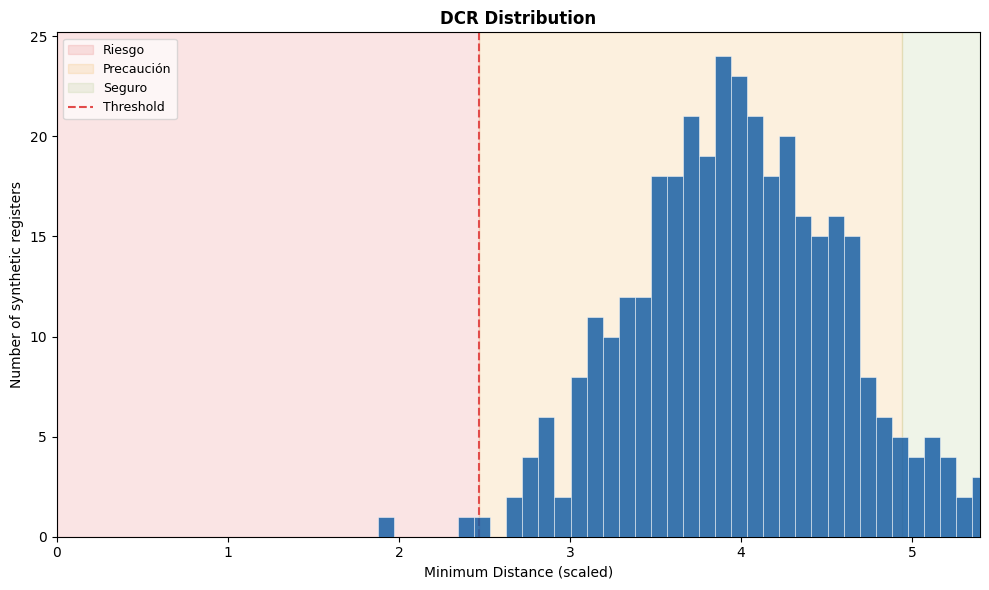

In [ ]:
# DFR = real dataset, DFS = synthetic dataset
def plot_dcr(min_dists, threshold=0.5, model_name="model", save_path=None):
    xmax = np.percentile(min_dists, 99)

    fig, ax = plt.subplots(figsize=(10, 6))

    # Background color
    ax.axvspan(0,             threshold,       alpha=0.15, color="#E24B4A", label="Riesgo")
    ax.axvspan(threshold,     threshold * 2,   alpha=0.15, color="#EF9F27", label="Precaución")
    ax.axvspan(threshold * 2, xmax * 1.05,     alpha=0.10, color="#639922", label="Seguro")

    # Histogram
    ax.hist(min_dists, bins=40, color="#185FA5", edgecolor="white",
            linewidth=0.4, alpha=0.85, zorder=3)

    # Threshold line
    ax.axvline(threshold, color="#E24B4A", linestyle="--", linewidth=1.5,
               label=f"Threshold")

    ax.set_xlim(0, xmax)
    ax.set_xlabel("Minimum Distance (scaled)", fontsize=10)
    ax.set_ylabel("Number of synthetic registers", fontsize=10)
    ax.set_title(f"DCR Distribution",
                 fontsize=12, fontweight="bold")
    ax.legend(fontsize=9, framealpha=0.7)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# ============================================================
# DCR
# ============================================================

def prepare_for_dcr(df_real, df_synth, cont_cols, cat_cols):
    """
    - Continuous: StandardScaler (mean 0, std 1).
    - Categorical: one-hot encoding (valores 0/1).
    """
    # Filter columns that exist in both dataframes
    cont_cols = [c for c in cont_cols if c in df_real.columns and c in df_synth.columns]
    cat_cols = [c for c in cat_cols if c in df_real.columns and c in df_synth.columns]

    # Combine real and synthetic before one-hot
    combined = pd.concat([df_real[cont_cols + cat_cols],
                          df_synth[cont_cols + cat_cols]],
                         axis=0, ignore_index=True)

    # One-hot encoding
    combined_encoded = pd.get_dummies(combined, columns=cat_cols)

    # Separate real and synthetic again
    n_real = len(df_real)
    real_enc = combined_encoded.iloc[:n_real].copy()
    synth_enc = combined_encoded.iloc[n_real:].copy()

    # Fill NaN before scaling
    real_enc = real_enc.fillna(0)
    synth_enc = synth_enc.fillna(0)

    scaler = StandardScaler()
    real_enc[cont_cols] = scaler.fit_transform(real_enc[cont_cols])
    synth_enc[cont_cols] = scaler.transform(synth_enc[cont_cols])

    return real_enc.values.astype(float), synth_enc.values.astype(float)


real_full, synth_full = prepare_for_dcr(df_real, df_synth, cont_cols, cat_cols)

dists = pairwise_distances(synth_full, real_full, metric='euclidean')
min_dists = dists.min(axis=1)

identical_records = np.sum(min_dists == 0)
risk_percent = (identical_records / len(df_synth)) * 100

dists_rr = pairwise_distances(real_full, real_full)
np.fill_diagonal(dists_rr, np.inf)
dcr_rr = dists_rr.min(axis=1)
threshold = np.percentile(dcr_rr, 5)

below_threshold = np.sum(min_dists < threshold)
below_pct = (below_threshold / len(df_synth)) * 100

# Report
print(f"=== DCR (continuous + categorical) ===")
print(f"Median DCR synthetic → real: {np.median(min_dists):.3f}")
print(f"Median DCR real → real:      {np.median(dcr_rr):.3f}")
print(f"Threshold adaptive (P5 real → real): {threshold:.3f}")
print(f"")
print(f"Exact copies (DCR = 0): {identical_records} ({risk_percent:.2f}%)")
print(f"Synthetic below threshold: {below_threshold} ({below_pct:.2f}%)")

# Plot
plot_dcr(
    min_dists  = min_dists,
    threshold  = threshold,
    model_name = model,
    save_path  = f"dcr_{model}.png"
)

In [ ]:
closest_real_idx = dists.argmin(axis=1)

variable_match_pct = []

for col in df_real.columns:
    matches = (df_synth[col].reset_index(drop=True).values ==
               df_real[col].iloc[closest_real_idx].reset_index(drop=True).values)
    pct = matches.sum() / len(df_synth) * 100
    variable_match_pct.append({'Variable': col, 'Match_%': round(pct, 2)})

variable_risk = pd.DataFrame(variable_match_pct).sort_values('Match_%', ascending=False)

print("=== Variables that risk privacy ===")
print("(% synthetic whose value concides with the closest real value)\n")
print(variable_risk.to_string(index=False))

# Guardar resultado
variable_risk.to_csv(f"variable_privacy_risk_{model}.csv", index=False)

=== Variables que más comprometen la privacidad ===
(% de sintéticos cuyo valor coincide con el del real más cercano)

            Variable  Coincidencia_%
      Kidney_failure           97.17
           Pneumonia           96.60
                 CKD           95.75
                COPD           95.47
        Early_end_CT           94.62
                Leak           94.05
                  IS           93.77
             R_grade           93.48
      Reintervention           93.48
                 IHD           92.92
           Procedure           92.92
         Readmission           91.78
     Paralytic_ileus           90.93
                 SSI           90.08
         CT_toxicity           87.25
             M_stage           85.84
         Adjuvant_CT           84.14
          Recurrence           83.29
                T2DM           82.72
                 HTN           80.74
               Death           80.74
                  Dl           80.17
       Complications          

In [ ]:
top5_risky = variable_risk.head(10)['Variable'].tolist()

print("\n=== Distribution of variables with most matches ===\n")
for col in top5_risky:
    if col in cat_cols:
        n_unique = df_real[col].nunique()
        most_common_pct = df_real[col].value_counts(normalize=True).iloc[0] * 100
        print(f"{col}: {n_unique} unique values, most common value in {most_common_pct:.1f}%")


=== Distribución en reales de las variables con más coincidencia ===

Kidney_failure: 2 valores únicos, valor más común aparece en 94.3% de reales
Pneumonia: 2 valores únicos, valor más común aparece en 94.3% de reales
CKD: 2 valores únicos, valor más común aparece en 96.6% de reales
COPD: 2 valores únicos, valor más común aparece en 93.5% de reales
Early_end_CT: 2 valores únicos, valor más común aparece en 91.5% de reales
Leak: 2 valores únicos, valor más común aparece en 96.0% de reales
IS: 2 valores únicos, valor más común aparece en 93.5% de reales
R_grade: 3 valores únicos, valor más común aparece en 94.2% de reales
Reintervention: 2 valores únicos, valor más común aparece en 93.2% de reales
IHD: 2 valores únicos, valor más común aparece en 89.2% de reales


**Metrics 2 and 3: Membership Inference Attack (MIA) and Attribute Inference Attack (AIA)**

Goal in MIA: minimize the ability to infer which data are real, i.e. it needs to be close to chance (0.5).

Goal in AIA: minimize the ability to infer data about real patients

In [ ]:
def evaluate_mia(DFR_train, DFR_test, DFS):
    # One-hot encoding
    X_train_proc, X_test_proc, X_syn_proc = prepare_data_for_ml_model(
        DFR_train, DFR_test, DFS
    )

    # Distance to closest
    nn = NearestNeighbors(n_neighbors=1).fit(X_syn_proc)
    dist_train, _ = nn.kneighbors(X_train_proc)
    dist_test,  _ = nn.kneighbors(X_test_proc)

    # Calculate scores
    scores = np.concatenate([-dist_train.flatten(), -dist_test.flatten()])
    labels = np.array([1] * len(dist_train) + [0] * len(dist_test))

    auc = roc_auc_score(labels, scores)
    return auc

def evaluate_aia(DFR_train, DFR_test, DFS, sensitive_col):
    is_continuous = sensitive_col in cont_cols

    X_syn_raw       = DFS.drop(columns=[sensitive_col])
    X_test_real_raw = DFR_test.drop(columns=[sensitive_col])

    _, X_test_real_proc, X_syn_proc = prepare_data_for_ml_model(
        pd.DataFrame(columns=X_syn_raw.columns),
        X_test_real_raw,
        X_syn_raw
    )

    y_syn       = DFS[sensitive_col]
    y_test_real = DFR_test[sensitive_col]

    if is_continuous:
        y_syn_proc  = pd.to_numeric(y_syn.astype(str).str.replace(',', '.'), errors='coerce')
        y_real_proc = pd.to_numeric(y_test_real.astype(str).str.replace(',', '.'), errors='coerce')
        y_syn_proc  = y_syn_proc.fillna(y_syn_proc.mean() if not y_syn_proc.isnull().all() else 0)
        y_real_proc = y_real_proc.fillna(y_real_proc.mean() if not y_real_proc.isnull().all() else 0)

        _, attacker_preds = random_forest(X_syn_proc, y_syn_proc, X_test_real_proc, clasif=False)
        attacker_score    = r2_score(y_real_proc, attacker_preds)
        baseline_score    = r2_score(y_real_proc, np.full(len(y_real_proc), y_syn_proc.mean()))

        return round(max(0.0, attacker_score - baseline_score), 4)

    else:
        if pd.api.types.is_object_dtype(y_syn) or pd.api.types.is_string_dtype(y_syn):
            mapper = {label: code for code, label in enumerate(y_syn.astype('category').cat.categories)}
        elif pd.api.types.is_numeric_dtype(y_syn) and y_syn.nunique() > 20:
            mapper = {label: code for code, label in enumerate(y_syn.astype('category').cat.categories)}
        else:
            mapper = None

        if mapper:
            y_syn_proc  = y_syn.map(mapper).fillna(-1).astype(int)
            y_real_proc = y_test_real.map(mapper).fillna(-1).astype(int)
        else:
            y_syn_proc  = y_syn.fillna(-1).astype(int)
            y_real_proc = y_test_real.fillna(-1).astype(int)

        _, attacker_preds = random_forest(X_syn_proc, y_syn_proc, X_test_real_proc, clasif=True)
        attacker_acc      = accuracy_score(y_real_proc, attacker_preds)

        baseline = DummyClassifier(strategy="most_frequent")
        baseline.fit(X_syn_proc, y_syn_proc)
        baseline_acc = accuracy_score(y_real_proc, baseline.predict(X_test_real_proc))

        return round(attacker_acc - baseline_acc, 4)

In [ ]:
def evaluate_full_dataset_privacy(DFR_train, DFR_test, DFS):
    mia_score = evaluate_mia(DFR_train, DFR_test, DFS)

    # --- AIA ---
    report = []
    all_cols = cat_cols + cont_cols
    columns_to_evaluate = [
        col for col in all_cols
        if col in DFR_train.columns and col in DFS.columns and col != 'Patient_ID'
    ]

    for col in columns_to_evaluate:
        if DFR_train[col].nunique() < 2 or DFS[col].nunique() < 2:
            continue
        inference_risk = evaluate_aia(DFR_train, DFR_test, DFS, col)
        report.append({'Column': col, 'Inference_Risk': inference_risk})

    report_df = pd.DataFrame(report).sort_values(by='Inference_Risk', ascending=False)

    return mia_score, report_df


mia_score, privacy_report_aia = evaluate_full_dataset_privacy(df_train, df_test, df_synth)

print(f"Global MIA Score: {mia_score:.4f}")

Global MIA Score: 0.5315


In [ ]:
# AIA usando reales en vez de sintéticos
aia_real_baseline = []
for col in privacy_report_aia['Column']:
    if col in df_train.columns:
        risk_real = evaluate_aia(df_train, df_test, df_train, col)
        risk_synth = privacy_report_aia[privacy_report_aia['Column'] == col]['Inference_Risk'].values[0]
        aia_real_baseline.append({
            'Column': col,
            'Risk_synth': risk_synth,
            'Risk_real': risk_real,
            'Difference': risk_synth - risk_real
        })

aia_comparison = pd.DataFrame(aia_real_baseline).sort_values('Difference', ascending=False)
print(aia_comparison.to_string(index=False))

              Column  Risk_synth  Risk_real  Difference
       Complications      0.2535     0.1690      0.0845
           TNM_stage      0.5775     0.5634      0.0141
           Procedure      0.0000    -0.0141      0.0141
                  Dl      0.0282     0.0141      0.0141
                T2DM      0.0141     0.0000      0.0141
             R_grade      0.0000     0.0000      0.0000
        Surgery_type      0.2254     0.2254      0.0000
         CT_toxicity      0.1549     0.1549      0.0000
                COPD      0.0000     0.0000      0.0000
     Paralytic_ileus      0.0000     0.0000      0.0000
      Kidney_failure      0.0000     0.0000      0.0000
                 SSI      0.0000     0.0000      0.0000
                Leak      0.0000     0.0000      0.0000
      Reintervention      0.0000     0.0000      0.0000
                 IHD      0.0000     0.0000      0.0000
                 CKD      0.0000     0.0000      0.0000
                  IS      0.0000     0.0000     

In [ ]:
aia_pass_rate_simple = (aia_comparison['Risk_synth'] < 0.05).mean() * 100
aia_pass_rate_real   = (aia_comparison['Difference'] < 0.05).mean() * 100

print(f"\n=== AIA Pass Rates ===")
print(f"Pass rate (Risk_synth < 0.05):    {aia_pass_rate_simple:.2f}%")
print(f"Pass rate corrected (Difference < 0.05):  {aia_pass_rate_real:.2f}%")
print(f"\nRecommended threshold: ≥ 90% (corrected)")


=== AIA Pass Rates ===
Pass rate ingenuo (Risk_synth < 0.05):    73.17%
Pass rate corregido (Difference < 0.05):  97.56%

Umbral recomendado: ≥ 90% (corregido)


In [ ]:
fallan = aia_comparison[aia_comparison['Difference'] >= 0.05]
print(f"Variables that fail ({len(fallan)}):")
print(fallan.to_string(index=False))

Variables que fallan (1):
       Column  Risk_synth  Risk_real  Difference
Complications      0.2535      0.169      0.0845


In [ ]:
privacy_report_aia

,Column,Inference_Risk
15,TNM_stage,0.5775
39,Survival_days,0.5523
40,Recurrence_free_days,0.5522
10,Site,0.5352
33,Death,0.3099
25,Complications,0.2535
22,Adjuvant_CT,0.2394
11,Surgery_type,0.2254
24,CT_toxicity,0.1549
12,T_stage,0.1549


In [ ]:
privacy_report_aia.to_csv("privacy_report_aia_%s.csv" % model)